<b>Original project:</b> <a href="https://colab.research.google.com/github/rpezoa/mlvalpo/blob/main/proyecto_parametros_estelares.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This notebook is a solution developed on top of the [original project](https://github.com/rpezoa/mlvalpo/blob/522dd6a46fcd92e42f5cdccd40ce13c5b5692aef/proyecto_parametros_estelares.ipynb) presented by **Raquel Pezoa** for the [2nd School of Applied Machine Learning for the Analysis of Massive Stars and Microlensing Events](https://ifa.uv.cl/mlvalpo/). Our main improvement is the implementation of hyperparameter optimisation through the use of Keras Tuner. The original notebook's body has been translated from Spanish into English; some sections have been shortened.

<div style="border-top:4px solid #1f4e79; border-bottom:1px solid #1f4e79; padding:18px 0 12px 0; margin-bottom:8px;">
<h1 style="text-align:center; font-family:Georgia, serif; margin:0 0 6px 0;">
Project: Inference of parameters of massive stars with a Convolutional Neural Network (CNN)
</h1>
<p style="text-align:center; font-size:14px; margin:2px 0;">
<b>Segunda Escuela de Machine Learning Aplicado al Análisis en Estrellas Masivas y eventos de Microlente</b>
</p>
<p style="text-align:center; font-size:13px; margin:4px 0 0 0;">
<i>Machine Learning fundamentals</i> session
</p>
<p style="text-align:center; font-size:13px; margin:4px 0 0 0;">
<b>Raquel Pezoa</b>, Departamento de Informática, Universidad Técnica Federico Santa María
</p>
<p style="text-align:center; font-size:12px; margin:6px 0 0 0; color:#777;">Synthetic spectra from the ISOSCELES grid (Araya et al. 2025)</p>
</div>

## Table of contents

1. [Project stages](#sec-1)
2. [Python libraries](#sec-2)
3. [Loading spectra](#sec-3)
4. [Obtaining the data](#sec-4)
5. [Exploratory data analysis (EDA)](#sec-5)
6. [Generation of training, validation and test sets](#sec-6)
7. [Design and implementation of the ML method](#sec-7)
8. [Validation on the test set](#sec-8)
9. [Validation on observed data](#sec-9)
10. [Open questions](#sec-10)
11. [Summary](#sec-11)

---

## Introduction

The estimation of stellar parameters from spectra is a fundamental task in astrophysics. In particular, the analysis of massive stars requires precise methods to estimate parameters such as the effective temperature ($T_\mathrm{eff}$), the rotation velocity ($v \sin i$), the surface gravity ($\log g$), the stellar luminosity and the terminal velocity of the stellar wind, among others.

In this project, a 1D convolutional neural network is trained to predict $T_\mathrm{eff}$, $\log g$ and the mass-loss rate ($\log \dot M$) from the H-alpha line, and its ability to generalise to observed spectra is evaluated.

**Learning objectives**

- Walk through the stages of a machine learning project, from data exploration to validation.
- Scale target variables with very different magnitudes.
- Design, train and diagnose a 1D CNN in Keras.
- Identify when a model extrapolates outside the training domain.

**Data.** A subset of the ISOSCELES database ([Araya et al. 2025](https://arxiv.org/abs/2511.03184)) restricted to the H-alpha line, with the microturbulence velocity fixed at 10 km/s, together with 76 observed spectra.

**About ISOSCELES.** ISOSCELES (*grId of Stellar atmOSphere and hydrodynamiC modELs for massivE Stars*) is a grid of synthetic spectra of solar-metallicity OBA-type stars, built with hydrodynamic wind solutions from the Hydwind code and line profiles from the Fastwind code ([Araya et al. 2025, arXiv:2511.03184](https://arxiv.org/abs/2511.03184)).

**About H-alpha.** The H-alpha line (6563 Å) of hydrogen is sensitive to the **stellar wind**: the greater the mass loss, the more the absorption is filled in with emission. For this reason, it is a good line for estimating $\log \dot M$.

<a id="sec-2"></a>

---
## 2. Python libraries

In [1]:
import tensorflow as tf
import keras
import keras_tuner

import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, r2_score

keras.utils.set_random_seed(42)
print(f"TensorFlow {tf.__version__} | GPU available: {bool(tf.config.list_physical_devices('GPU'))}")

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

TensorFlow 2.16.2 | GPU available: True


<a id="sec-3"></a>

---
## 3. Loading spectra

Three files are downloaded:

| File | Contents |
|---|---|
| `subset_vmic10.npy` | 10,000 synthetic H-alpha spectra, 200 flux points each |
| `y_subset_vmic10.npy` | 9 parameters of each synthetic spectrum |
| `X_observed.npy` | 76 observed spectra, 8 lines per star |

> **Note.** `getFile` first looks for the files on the computer and, if it does not find them, downloads them from Google Drive.

In [2]:
def getFile(fileName, driveId, localFolders=()):
    """
    Returns the local path of a data file.

    Looks for `fileName` in the folder given by the MLVALPO_DATA environment
    variable, then in `localFolders` and in the current folder. If it is not
    found, it is downloaded from Google Drive.

    Parameters
    ----------
    fileName       : str   -- name of the file
    driveId        : str   -- identifier of the file on Google Drive
    localFolders   : list  -- additional folders to search in

    Returns
    -------
    str -- path of the file
    """
    folders = [os.environ.get("MLVALPO_DATA", ""), *localFolders, "."]
    for folder in folders:
        path = os.path.join(folder, fileName)
        if folder and os.path.exists(path):
            print(f"{fileName} found in {folder}")
            return path
    import gdown  # pre-installed on Colab; locally: pip install gdown
    print(f"Downloading {fileName} from Google Drive...")
    gdown.download(f"https://drive.google.com/uc?id={driveId}", fileName, quiet=True)
    return fileName


# Dataset provided by PhD (c) Daniela Turis, IFA-UV.
SYNTHETIC_FOLDER = "/Users/rpezoa/experiment_data/data_fo/data_vmic10/"
OBSERVED_FOLDER = "/Users/rpezoa/experiment_data/data_fo/data/"

data = np.load(getFile("subset_vmic10.npy", "14NHeV1fvE2HXMaghHAszf_92iTBVNJHL", [SYNTHETIC_FOLDER]))
y = np.load(getFile("y_subset_vmic10.npy", "1g56JSd46v1HjJkhpIw7Qkal--VDd7cpS", [SYNTHETIC_FOLDER]))
dataObserved = np.load(getFile("X_observed.npy", "1YA9HYeOKHMYvt9M4LAaLkO8mpJjOXktV", [OBSERVED_FOLDER]))

# Pre-processed version of the observed H-alpha (for now only available locally)
processedPath = os.path.join(OBSERVED_FOLDER, "X_observed_processed.npy")
processedObservedData = np.load(processedPath) if os.path.exists(processedPath) else None
print("Pre-processed observed H-alpha:", "available" if processedObservedData is not None else "not available (the raw line will be used)")

subset_vmic10.npy found in .
y_subset_vmic10.npy found in .
X_observed.npy found in .
Pre-processed observed H-alpha: not available (the raw line will be used)


<a id="sec-4"></a>

---
## 4. Obtaining the data

`data` contains the spectra and `y` the parameters of each one.

In [3]:
print("data:", data.shape, "  (spectra, flux points)")
print("y:   ", y.shape, "  (spectra, parameters)")

data: (10000, 200)   (spectra, flux points)
y:    (10000, 9)   (spectra, parameters)


In [4]:
PARAMETERS = ["TEFF", "LOGG", "LOGLSTAR", "ALPHA", "K", "DELTA", "VINF", "LOGMDOT", "SI"]
DESCRIPTION = [
    "Effective temperature [K]",
    "Logarithm of the surface gravity",
    "Logarithm of the stellar luminosity",
    "Alpha line-strength parameter",
    "k line-strength parameter",
    "Delta line-strength parameter",
    "Terminal velocity of the wind [km/s]",
    "Logarithm of the mass-loss rate",
    "Silicon abundance",
]
summary = pd.DataFrame({"Description": DESCRIPTION, "Minimum": y.min(axis=0), "Maximum": y.max(axis=0),
                        "Distinct values": [len(np.unique(c)) for c in y.T]}, index=PARAMETERS)
summary.style.format({"Minimum": "{:.2f}", "Maximum": "{:.2f}"})

,Description,Minimum,Maximum,Distinct values
TEFF,Effective temperature [K],9000.00,45000.00,58
LOGG,Logarithm of the surface gravity,1.65,4.20,18
LOGLSTAR,Logarithm of the stellar luminosity,2.76,5.65,476
ALPHA,Alpha line-strength parameter,0.45,0.57,6
K,k line-strength parameter,0.05,0.60,12
DELTA,Delta line-strength parameter,0.29,0.35,7
VINF,Terminal velocity of the wind [km/s],172.49,673.07,7111
LOGMDOT,Logarithm of the mass-loss rate,-11.32,-4.99,7111
SI,Silicon abundance,7.21,7.81,5


* Only **TEFF**, **LOGG** and **LOGMDOT** (columns 0, 1 and 7) should be selected.
* As ISOSCELES is a **grid**, some parameters take only a few distinct values (for example, $\log g$ takes 18).

In [5]:
yNew = y[:, [0, 1, 7]]
NAMES = ["$T_{eff}$ [K]", "$\\log g$", "$\\log \\dot{M}$"]
COLOURS = ["skyblue", "lightgreen", "salmon"]
yNew.shape

(10000, 3)

### 4.1 Example of a synthetic spectrum

The curves are the H-alpha line sampled at 200 points. The synthetic spectra do not include the wavelength of each point, so the horizontal axis shows the **pixel index**.

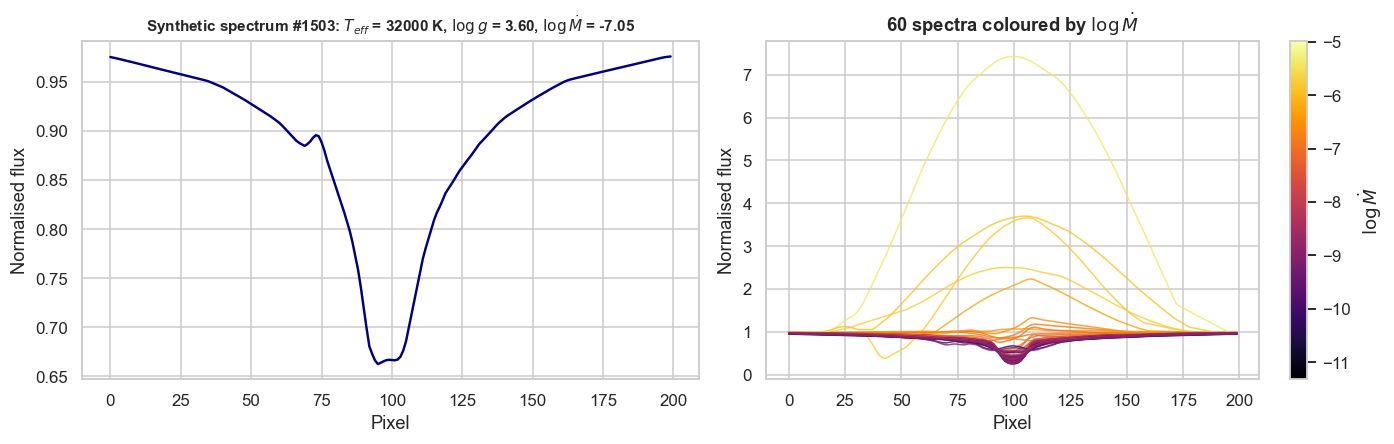

TEFF        32000.000
LOGG            3.600
LOGLSTAR        5.004
ALPHA           0.450
K               0.250
DELTA           0.330
VINF          416.556
LOGMDOT        -7.049
SI              7.360
dtype: float64

In [6]:
i = 1503
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# One spectrum
axes[0].plot(range(200), data[i, :], color="navy", lw=1.6)
axes[0].set(title=f"Synthetic spectrum #{i}: $T_{{eff}}$ = {y[i, 0]:.0f} K, "
                  f"$\\log g$ = {y[i, 1]:.2f}, $\\log \\dot{{M}}$ = {y[i, 7]:.2f}",
            xlabel="Pixel", ylabel="Normalised flux")
axes[0].title.set_fontsize(10)

# Several spectra coloured by mass loss
rng = np.random.default_rng(0)
idx = rng.choice(len(data), 60, replace=False)
norm = plt.Normalize(y[:, 7].min(), y[:, 7].max())
cmap = plt.cm.inferno
for j in idx:
    axes[1].plot(range(200), data[j, :], color=cmap(norm(y[j, 7])), lw=1, alpha=0.8)
axes[1].set(title="60 spectra coloured by $\\log \\dot{M}$", xlabel="Pixel", ylabel="Normalised flux")
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes[1], label="$\\log \\dot{M}$")

plt.tight_layout()
plt.show()

pd.Series(y[i], index=PARAMETERS).round(3)

<a id="sec-5"></a>

---
## 5. Exploratory data analysis (EDA)

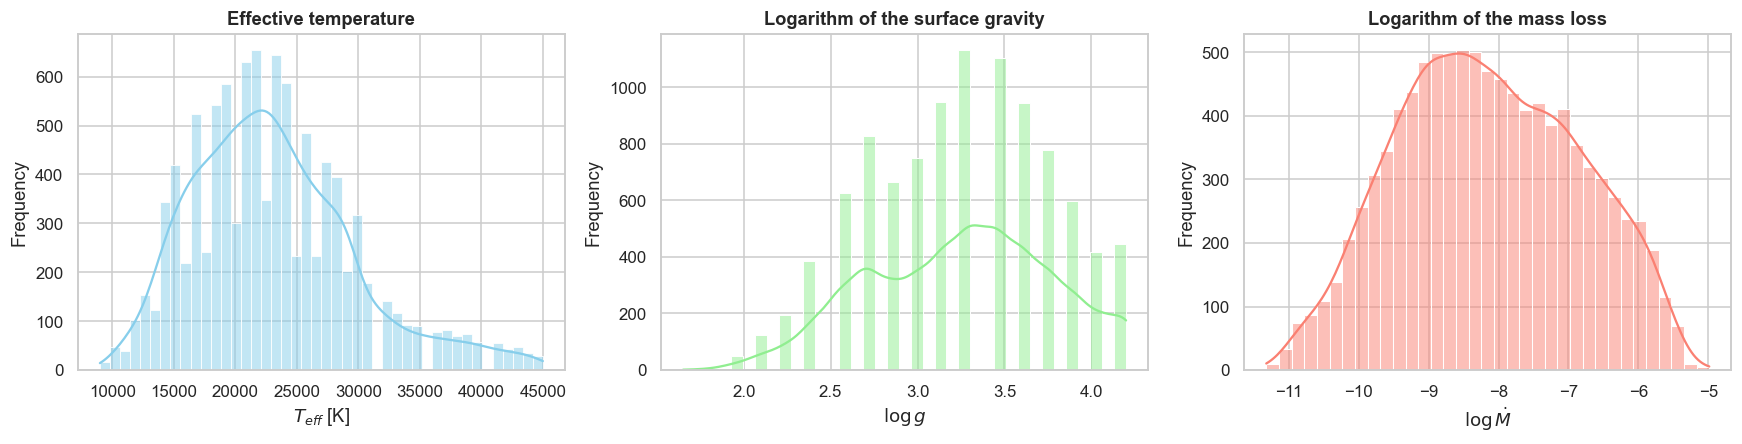

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for k, ax in enumerate(axes):
    sns.histplot(yNew[:, k], kde=True, color=COLOURS[k], ax=ax)
    ax.set(title=["Effective temperature", "Logarithm of the surface gravity", "Logarithm of the mass loss"][k],
           xlabel=NAMES[k], ylabel="Frequency")
plt.tight_layout()
plt.show()

<a id="sec-6"></a>

---
## 6. Generation of training, validation and test sets

### 6.1 Scaling the data

* The output values are scaled.
* The three parameters live on very different scales ($T_\mathrm{eff} \sim 10^4$ K, $\log g \sim 3$, $\log \dot M \sim -8$). If they are not scaled, the loss function is dominated by $T_\mathrm{eff}$. `MinMaxScaler` maps each parameter to the interval $[0, 1]$:

$$
y' = \frac{y - y_{\min}}{y_{\max} - y_{\min}}.
$$

At the end, `scaler.inverse_transform` returns the predictions to their physical units.

In [8]:
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(yNew)
yScaled = scaler.transform(yNew)

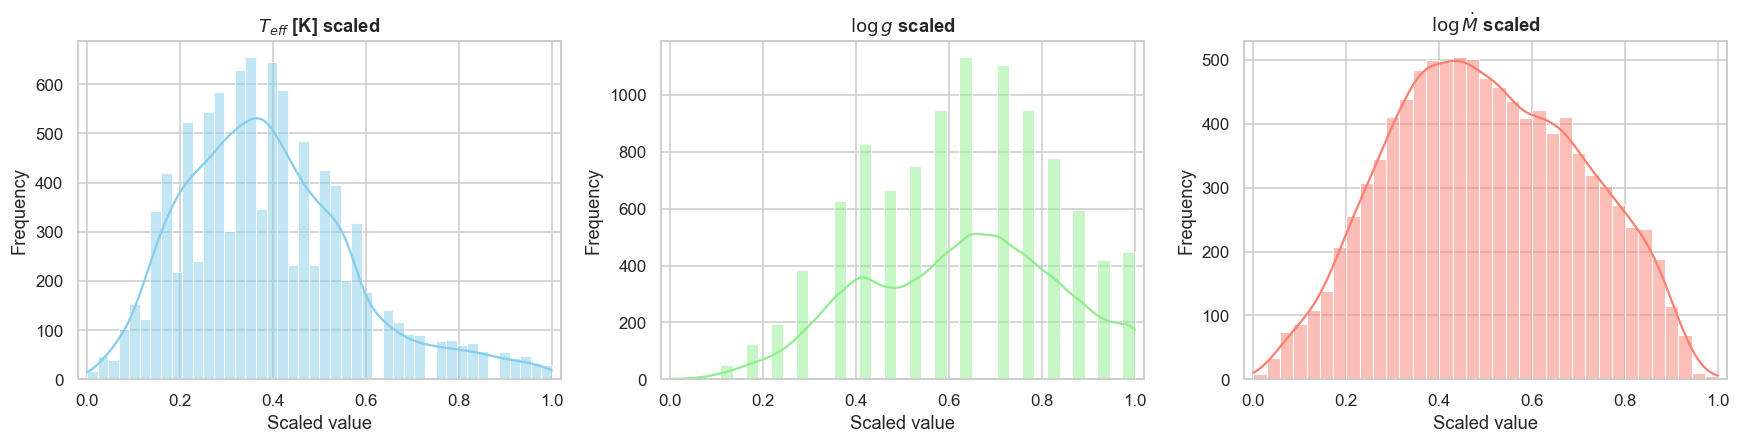

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for k, ax in enumerate(axes):
    sns.histplot(yScaled[:, k], kde=True, color=COLOURS[k], ax=ax)
    ax.set(title=f"{NAMES[k]} scaled", xlabel="Scaled value", ylabel="Frequency", xlim=(-0.02, 1.02))
plt.tight_layout()
plt.show()

### 6.2 Partitioning the data

As in the previous notebooks: 64% training, 16% validation and 20% testing.

In [10]:
XTrain, XTest, yTrain, yTest = train_test_split(data, yScaled, test_size=0.2, random_state=42)
XTrain, XVal, yTrain, yVal = train_test_split(XTrain, yTrain, test_size=0.2, random_state=42)

<a id="sec-7"></a>

---
## 7. Design and implementation of the ML method

### 7.1 Input format for a 1D CNN

A Keras `Conv1D` layer expects data with shape **(samples, steps, channels)**. Each spectrum is a sequence of 200 steps with a single channel (the flux), so we go from `(n, 200)` to `(n, 200, 1)`.

In [11]:
timeSteps = XTrain.shape[1]
inputDimension = 1

sampleSize = XTrain.shape[0]
XTrainReshaped = XTrain.reshape((sampleSize, timeSteps, inputDimension))
sampleSize = XVal.shape[0]
XValReshaped = XVal.reshape((sampleSize, timeSteps, inputDimension))
sampleSize = XTest.shape[0]
XTestReshaped = XTest.reshape((sampleSize, timeSteps, inputDimension))

print("Training:  ", XTrainReshaped.shape)
print("Validation:", XValReshaped.shape)
print("Testing:   ", XTestReshaped.shape)

Training:   (6400, 200, 1)
Validation: (1600, 200, 1)
Testing:    (2000, 200, 1)


# Training the model

In [12]:
def buildConv1DModel(hp):
    """Builds and compiles the 1D CNN: 200-pixel spectrum -> scaled [T_eff, log g, log Mdot]."""
    nTimesteps = XTrainReshaped.shape[1]  # 200
    nFeatures = XTrainReshaped.shape[2]   # 1
    model = keras.Sequential(name="modelConv1D")
    model.add(keras.layers.Input(shape=(nTimesteps, nFeatures)))
    
    for i in range(hp.Int("numLayers", 2, 4, 1)):    
        model.add(keras.layers.Conv1D(filters=hp.Int(name="filters"+str(i),min_value=16, max_value=128, step=2, sampling="log"),
        kernel_size=hp.Int("kernel"+str(i), 3, 7, step=2),
        activation=hp.Choice("activation"+str(i), ["elu", "relu", "tanh"]), 
        name="Conv1D_"+str(i)))
        if(hp.Boolean("batchNormalization")):
            model.add(keras.layers.BatchNormalization())
        model.add(keras.layers.Dropout(rate=hp.Float("rate"+str(i), 0.0, 0.4,0.1)))
    
    model.add(keras.layers.Flatten())
    model.add(keras.layers.Dense(32, activation="selu", name="Dense_1"))
    model.add(keras.layers.Dense(3, activation="linear", name="Dense_4"))

    
    if hp.Choice("optimizer", ["rms", "adam"]) == "rms": 
        optimizer = tf.keras.optimizers.RMSprop(0.001)
    else: optimizer = keras.optimizers.Adam()
    model.compile(loss='mse', optimizer= optimizer, metrics=['mse'])
    return model

tuner = keras_tuner.BayesianOptimization(
    hypermodel=buildConv1DModel,
    objective="val_loss",
    max_trials=20,
    seed=43,
    max_retries_per_trial=1,
    overwrite=True,
    directory="project1Models",
    project_name="convTuned",
)

tuner.search(XTrainReshaped, 
             yTrain, 
             epochs=50, 
             validation_data=(XValReshaped, yVal),
             callbacks=[keras.callbacks.EarlyStopping(patience=7),
             keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=7)])

bestModel = tuner.get_best_models(num_models=1)[0]
bestModel.save("bestTunedModel.keras")
bestHyperparameters = tuner.get_best_hyperparameters()
print(bestHyperparameters)

Trial 20 Complete [00h 20m 15s]
val_loss: 0.006455980706959963

Best val_loss So Far: 0.0018498365534469485
Total elapsed time: 01h 13m 12s


/opt/homebrew/Caskroom/miniconda/base/envs/machineLearning/lib/python3.10/site-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


### 7.3 Training

* An **epoch** is one complete pass through the training set.
* `EarlyStopping` halts training if the loss does not improve for 5 consecutive epochs (`patience=5`).

In [13]:
modelConv1D = bestModel
modelConv1D.summary()

Model: "modelConv1D"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Conv1D_0 (Conv1D)               │ (None, 198, 64)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 198, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1D_1 (Conv1D)               │ (None, 196, 16)        │         3,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 196, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_1 (Dense)                 │ (None, 32)             │       100,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_4 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 103,827 (405.57 KB)

 Trainable params: 103,827 (405.57 KB)

 Non-trainable params: 0 (0.00 B)

### 7.4 Learning curves

If the validation loss decreases along with the training loss, the model is learning patterns that generalise. If the training loss keeps decreasing whilst the validation loss rises, there is **overfitting**.

Epoch 1/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.0027 - mse: 0.0027 - val_loss: 0.0025 - val_mse: 0.0025 - learning_rate: 0.0010
Epoch 2/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0028 - mse: 0.0028 - val_loss: 0.0020 - val_mse: 0.0020 - learning_rate: 0.0010
Epoch 3/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0025 - mse: 0.0025 - val_loss: 0.0019 - val_mse: 0.0019 - learning_rate: 0.0010
Epoch 4/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0034 - mse: 0.0034 - val_loss: 0.0020 - val_mse: 0.0020 - learning_rate: 0.0010
Epoch 5/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0027 - mse: 0.0027 - val_loss: 0.0018 - val_mse: 0.0018 - learning_rate: 0.0010
Epoch 6/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0022 - mse: 0.0022 - val_loss: 0.0023 - val_mse: 0.0023 - learning_rate: 0.0010
Epoch 7/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0023 - mse: 0.0023 - val_loss: 0.0019 - val_mse: 0.0019 - learning_rate: 0.0010
Epoch 

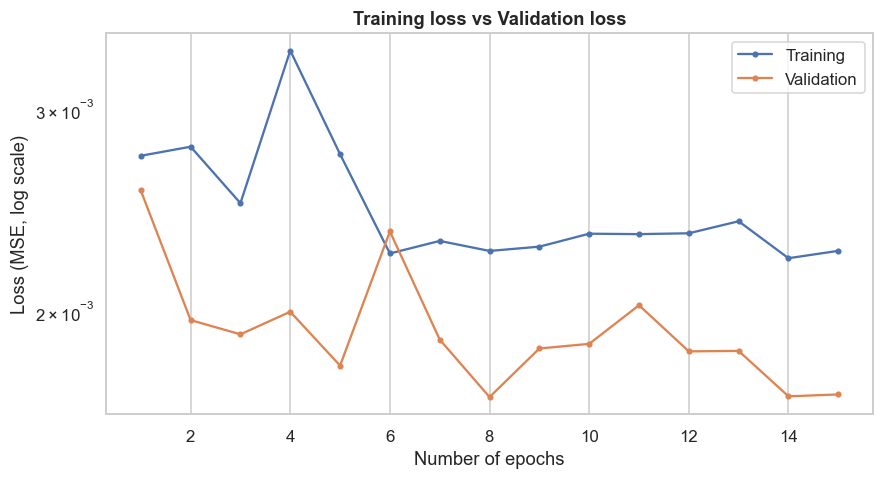

In [14]:
def plotTrainVal(A, B, xlabel, ylabel, title):
    """
    Plots two curves per epoch (training and validation) on a logarithmic scale.

    Parameters
    ----------
    A, B           : lists -- per-epoch training and validation values
    xlabel, ylabel : str   -- axis labels
    title          : str   -- plot title
    """
    epochs = range(1, len(A) + 1)
    plt.figure(figsize=(9, 4.5))
    plt.plot(epochs, A, "o-", ms=3, label="Training")
    plt.plot(epochs, B, "o-", ms=3, label="Validation")
    plt.yscale("log")
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.show()

history = bestModel.fit(XTrainReshaped, 
                          yTrain, 
                          epochs=50, 
                          validation_data=(XValReshaped, yVal),
                          batch_size=20,
                          callbacks=[keras.callbacks.EarlyStopping(patience=7, restore_best_weights=False),
                                     keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=7)])

trainLoss = history.history['loss']
valLoss = history.history['val_loss']
print(f"Epochs trained: {len(trainLoss)}")
plotTrainVal(trainLoss, valLoss, 'Number of epochs', 'Loss (MSE, log scale)',
               'Training loss vs Validation loss')

<a id="sec-8"></a>

---
## 8. Validation on the test set

We predict the test spectra and convert back to physical units with `inverse_transform`.

In [15]:
loss, mse = modelConv1D.evaluate(XTestReshaped, yTest, verbose=0)
print(f"MSE on the test set (scaled outputs): {mse:.5f}")

pred = modelConv1D.predict(XTestReshaped, verbose=0)
a = scaler.inverse_transform(pred)    # predicted, in physical units
b = scaler.inverse_transform(yTest)  # true, in physical units

metrics = pd.DataFrame({
    "MAE": [mean_absolute_error(b[:, k], a[:, k]) for k in range(3)],
    "R²": [r2_score(b[:, k], a[:, k]) for k in range(3)],
}, index=["T_eff [K]", "log g", "log Mdot"])
metrics.style.format({"MAE": "{:.3f}", "R²": "{:.3f}"})

MSE on the test set (scaled outputs): 0.00166


,MAE,R²
T_eff [K],687.574,0.973
log g,0.063,0.970
log Mdot,0.238,0.932


### 8.1 True value versus predicted value

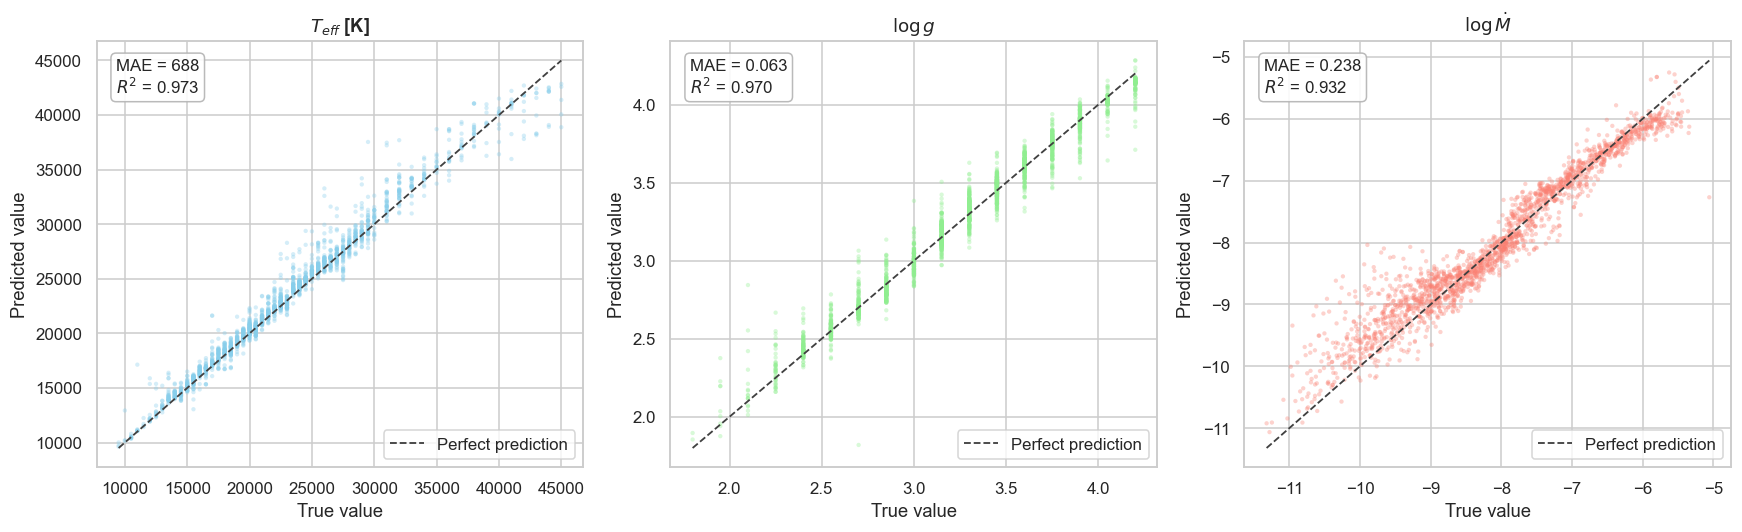

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for k, ax in enumerate(axes):
    ax.scatter(b[:, k], a[:, k], s=8, alpha=0.35, color=COLOURS[k], edgecolor="none")
    lim = [b[:, k].min(), b[:, k].max()]
    ax.plot(lim, lim, "--", color="0.25", lw=1.2, label="Perfect prediction")
    ax.text(0.04, 0.96, f"MAE = {metrics.iloc[k, 0]:.3g}\n$R^2$ = {metrics.iloc[k, 1]:.3f}",
            transform=ax.transAxes, va="top", fontsize=11,
            bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.9))
    ax.set(title=NAMES[k], xlabel="True value", ylabel="Predicted value")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 8.2 Comparison of distributions

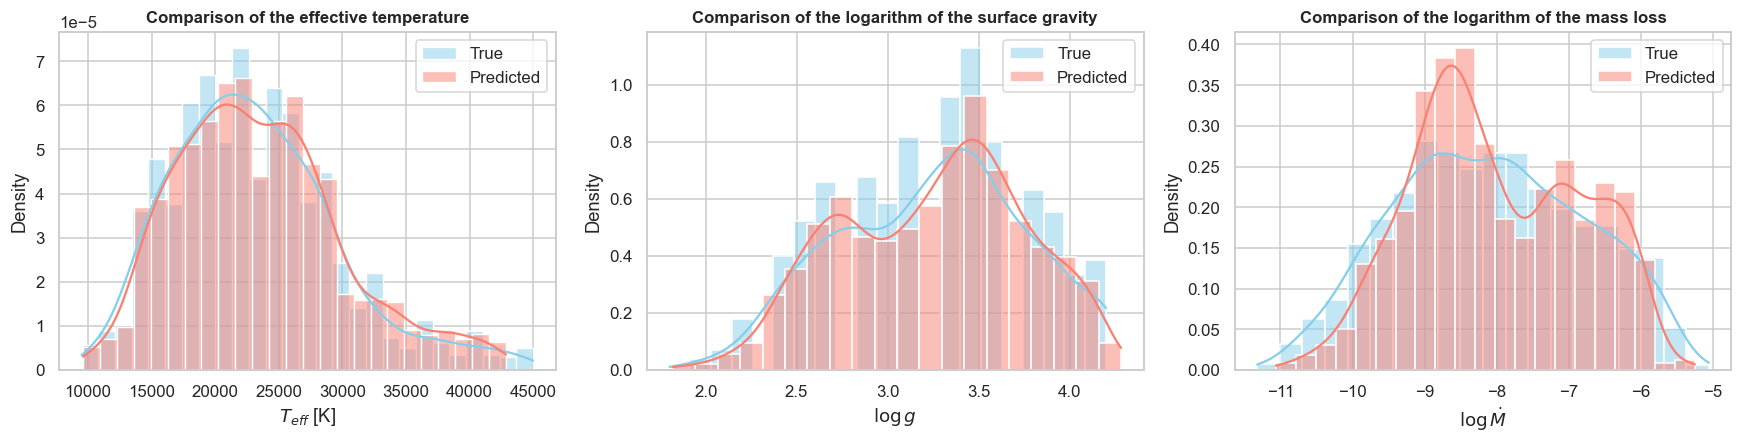

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
titles = ["Comparison of the effective temperature", "Comparison of the logarithm of the surface gravity",
           "Comparison of the logarithm of the mass loss"]
for k, ax in enumerate(axes):
    sns.histplot(b[:, k], kde=True, color="skyblue", label="True", stat="density", ax=ax)
    sns.histplot(a[:, k], kde=True, color="salmon", label="Predicted", stat="density", ax=ax)
    ax.set(title=titles[k], xlabel=NAMES[k], ylabel="Density")
    ax.title.set_fontsize(11)
    ax.legend()
plt.tight_layout()
plt.show()

**How to read the plots.** In the true-versus-predicted plot, $T_\mathrm{eff}$ and $\log g$ take only a few distinct values in the grid (see the table in section 4), so in those panels the points cluster in vertical columns; the vertical width of each column is the scatter of the predictions for one and the same true value. The histograms compare the whole distribution: if the model tends towards the mean, the predicted histogram is narrower than the true one.

<a id="sec-9"></a>

---
## 9. Validation on observed data

* The observed data come with **8 lines** per star and **200 flux points** per line.
* The lines, in order, are: Si IV 4089, H-gamma, He I 4387, He I 4471, Si III 4552, H-beta, H-alpha and He I 6678.
* Only the **H-alpha** line (index 6) must be extracted for evaluation, since our training data contain only H-alpha.

In [18]:
LINES = ["Si IV 4089", "H-gamma", "He I 4387", "He I 4471", "Si III 4552", "H-beta", "H-alpha", "He I 6678"]
print("dataObserved:", dataObserved.shape, "  (stars, lines, flux points)")

dataObserved: (76, 8, 200)   (stars, lines, flux points)


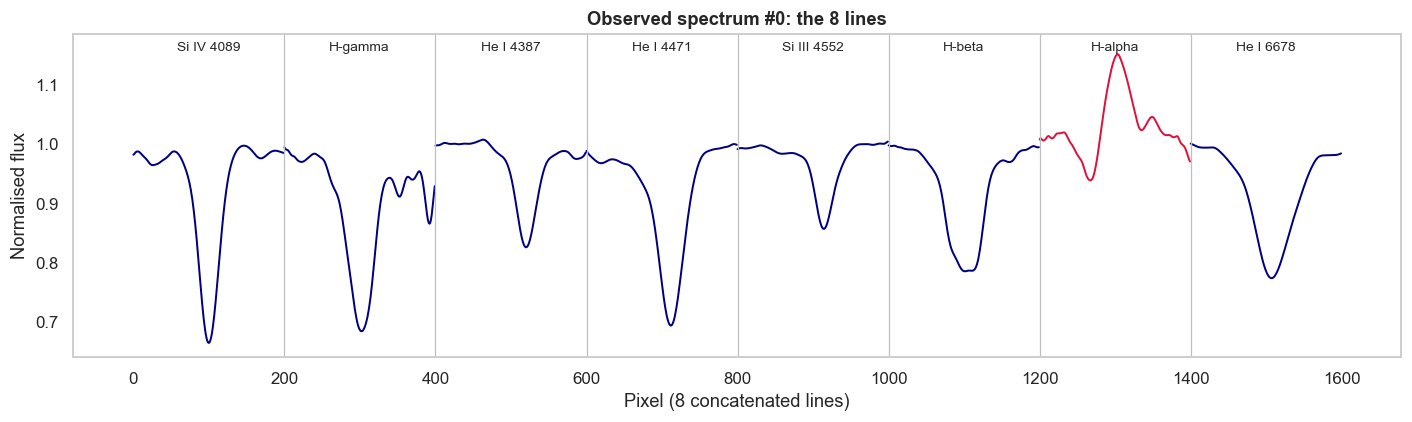

In [19]:
star = 0
plt.figure(figsize=(13, 4))
for k, line in enumerate(LINES):
    x = np.arange(200) + 200 * k
    plt.plot(x, dataObserved[star, k, :], lw=1.3, color="crimson" if line == "H-alpha" else "navy")
    plt.text(x.mean(), dataObserved[star].max() * 1.005, line, ha="center", fontsize=9)
    if k > 0:
        plt.axvline(200 * k, color="0.75", lw=0.8)
plt.xlabel("Pixel (8 concatenated lines)")
plt.ylabel("Normalised flux")
plt.title(f"Observed spectrum #{star}: the 8 lines")
plt.ylim(top=dataObserved[star].max() * 1.03)
plt.grid(False)
plt.tight_layout()
plt.show()

### 9.1 Observed H-alpha line

If the **pre-processed** version of H-alpha exists (`X_observed_processed.npy`), it is used. Otherwise, the unprocessed H-alpha line extracted from `X_observed.npy` is used.

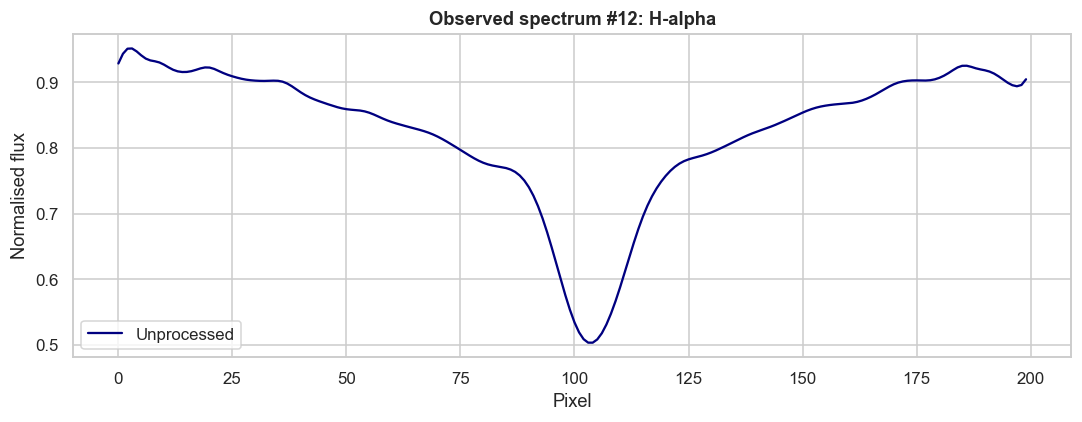

In [20]:
halphaObs = processedObservedData if processedObservedData is not None else dataObserved[:, 6, :]

star = 12
plt.figure(figsize=(10, 4))
plt.plot(range(200), dataObserved[star, 6, :], color="navy", lw=1.5, label="Unprocessed")
if processedObservedData is not None:
    plt.plot(range(200), processedObservedData[star, :], color="crimson", lw=1.5, label="Pre-processed")
plt.xlabel("Pixel")
plt.ylabel("Normalised flux")
plt.title(f"Observed spectrum #{star}: H-alpha")
plt.legend()
plt.tight_layout()
plt.show()

### 9.2 Prediction for one star

In [21]:
obsXReshaped = halphaObs[star, :].reshape((1, timeSteps, inputDimension))
predObs = modelConv1D.predict(obsXReshaped, verbose=0)
predObsInv = scaler.inverse_transform(predObs)
pd.Series(predObsInv.ravel(), index=["Teff [K]", "log g", "log Mdot"], name=f"Star #{star}").round(2)

Teff [K]    37075.398438
log g           4.700000
log Mdot       -9.710000
Name: Star #12, dtype: float32

### 9.3 Prediction for the 76 stars

We pass all the stars through the network at once and store the predictions in a `DataFrame`.

In [22]:
obsReshaped = halphaObs.reshape((halphaObs.shape[0], timeSteps, inputDimension))
predictions = scaler.inverse_transform(modelConv1D.predict(obsReshaped, verbose=0))

dfPredictions = pd.DataFrame(predictions, columns=["Teff", "Logg", "MassLoss"])
dfPredictions.index.name = "spectrumID"
dfPredictions.round({"Teff": 0, "Logg": 2, "MassLoss": 2})

,Teff,Logg,MassLoss
spectrumID,,,
0,34819.0,3.90,-6.54
1,35676.0,3.68,-6.06
2,35303.0,3.72,-6.05
3,34507.0,4.37,-8.03
4,36741.0,4.25,-8.59
...,...,...,...
71,27353.0,4.87,-9.90
72,28975.0,4.94,-10.92
73,40956.0,3.52,-6.76


### 9.4 Coverage of the training domain

We compare the distribution of the predictions for the observed stars with the distribution of the parameters of the training set. A prediction outside the range of the grid is a warning sign: the model is **extrapolating**.

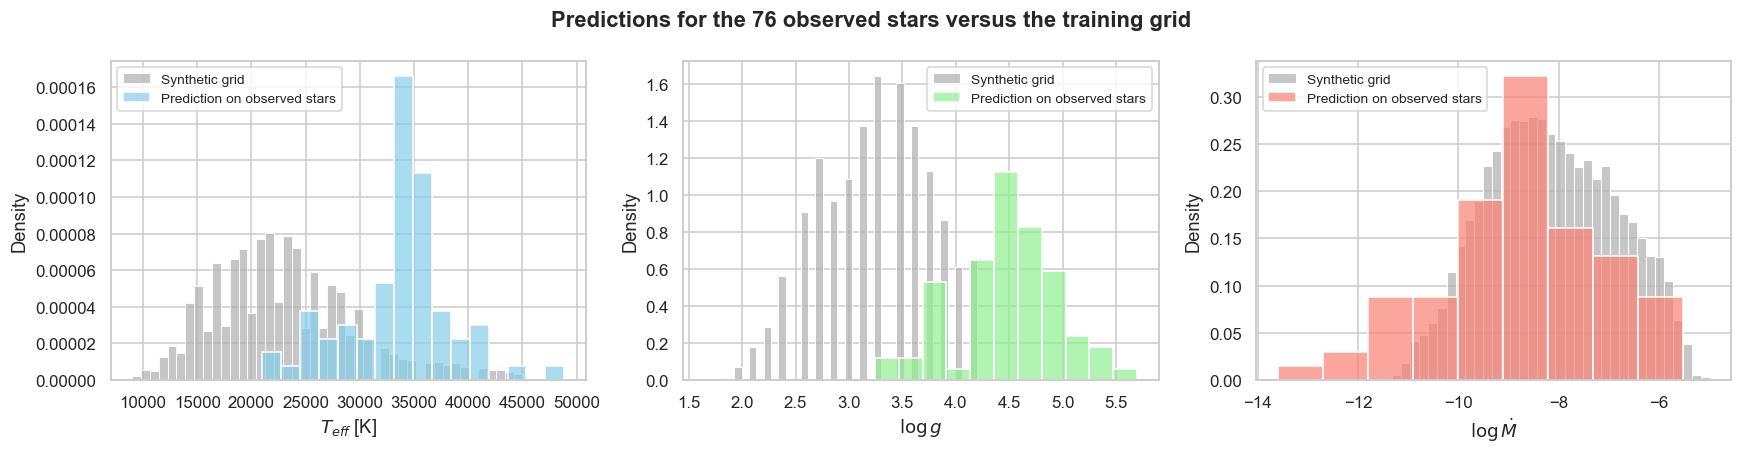

Stars with at least one parameter outside the range of the grid: 59 out of 76


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for k, ax in enumerate(axes):
    sns.histplot(yNew[:, k], color="0.7", stat="density", label="Synthetic grid", ax=ax)
    sns.histplot(predictions[:, k], color=COLOURS[k], stat="density", label="Prediction on observed stars",
                 ax=ax, alpha=0.7)
    ax.set(xlabel=NAMES[k], ylabel="Density")
    ax.legend(fontsize=9)
plt.suptitle("Predictions for the 76 observed stars versus the training grid", fontweight="bold")
plt.tight_layout()
plt.show()

outsideGrid = ((predictions < yNew.min(axis=0)) | (predictions > yNew.max(axis=0))).any(axis=1)
print(f"Stars with at least one parameter outside the range of the grid: {outsideGrid.sum()} out of {len(outsideGrid)}")

<a id="sec-10"></a>

---
## 10. Open questions

1. `EarlyStopping` monitors the **training** loss (`monitor='loss'`). What changes if it monitors `val_loss` and `restore_best_weights=True` is added?
2. Add `BatchNormalization` or `Dropout` layers and compare the learning curves.
3. $\log g$ takes only 18 values in the grid. Is it better to treat it as **classification** rather than regression?
4. The synthetic spectra are noise-free and the observed ones are not. How could noise be added to the synthetic spectra during training to improve generalisation?

**Answers**

1.
2.
3.
4.

<a id="sec-11"></a>

---
## 11. Summary

1. **Stages.** A machine learning project moves through data acquisition, exploratory analysis, partitioning, model design and validation, first on synthetic data and then on observed data.
2. **Scaling.** The outputs live on very different scales; `MinMaxScaler` maps them to $[0, 1]$ so that none dominates the loss, and `inverse_transform` returns them to physical units.
3. **1D CNN.** The convolutional filters share weights along the spectrum and detect local patterns of the line profile.
4. **Learning curves.** Comparing the training and validation loss per epoch makes it possible to detect overfitting.
5. **Training domain.** A prediction outside the range of the grid indicates that the model is extrapolating.

---

### References

- Araya, I., Curé, M., Machuca, N., et al. (2025). *ISOSCELES project: A grid-based quantitative spectroscopic analysis of massive stars.* [arXiv:2511.03184](https://arxiv.org/abs/2511.03184)
- LeCun, Y., Bottou, L., Bengio, Y., & Haffner, P. (1998). *Gradient-based learning applied to document recognition.* Proceedings of the IEEE, 86(11), 2278–2324. [doi:10.1109/5.726791](https://doi.org/10.1109/5.726791)
- Klambauer, G., Unterthiner, T., Mayr, A., & Hochreiter, S. (2017). *Self-normalizing neural networks.* NeurIPS 30. [arXiv:1706.02515](https://arxiv.org/abs/1706.02515)
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.). Springer. [doi:10.1007/978-0-387-84858-7](https://doi.org/10.1007/978-0-387-84858-7)